In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv('Wholesale customers data.csv')

In [3]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
df.shape

(440, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [7]:
df.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [8]:
df.duplicated().sum()

np.int64(0)

<Axes: ylabel='Fresh'>

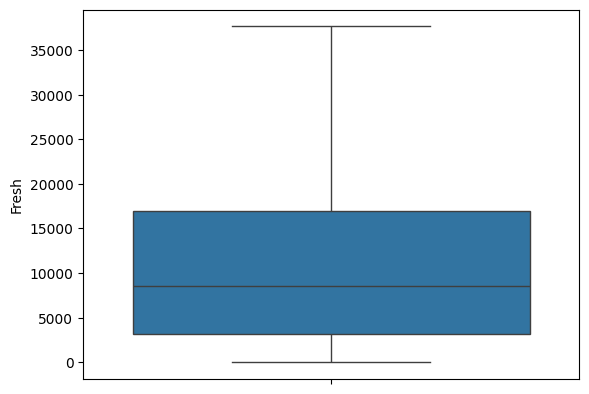

In [18]:
sns.boxplot(df['Fresh'])

<Axes: ylabel='Milk'>

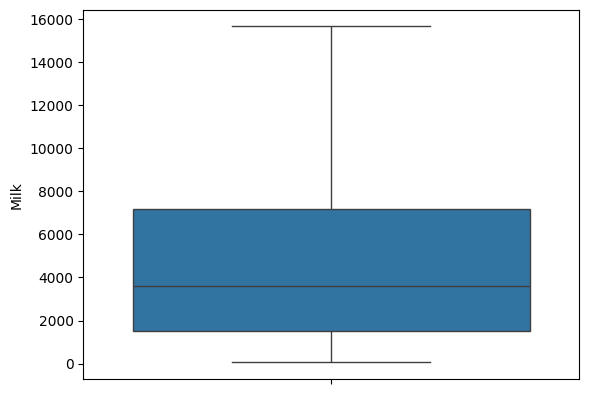

In [19]:
sns.boxplot(df['Milk'])

<Axes: ylabel='Grocery'>

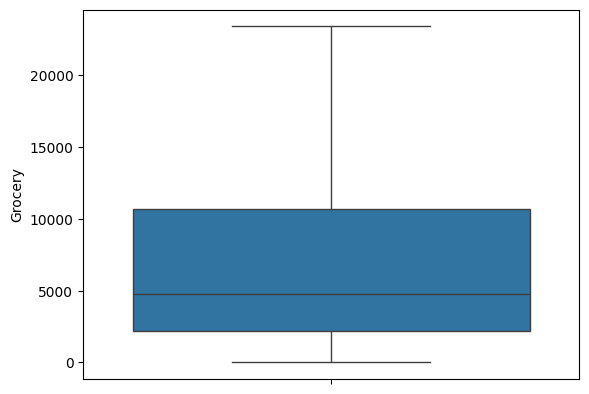

In [20]:
sns.boxplot(df['Grocery'])

<Axes: ylabel='Frozen'>

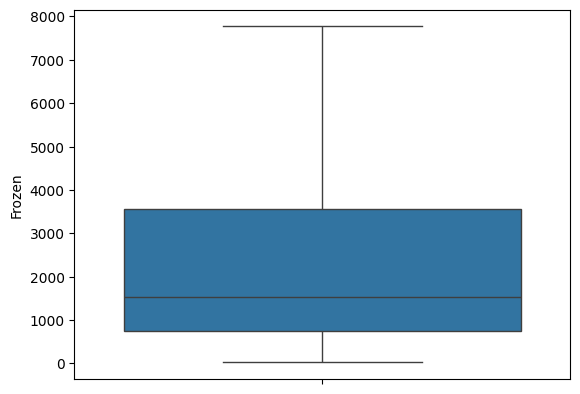

In [21]:
sns.boxplot(df['Frozen'])

<Axes: ylabel='Detergents_Paper'>

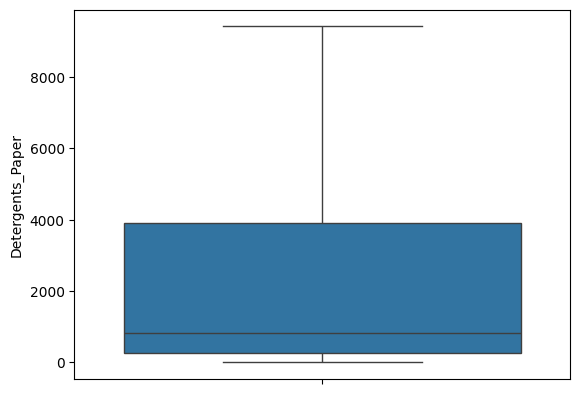

In [22]:
sns.boxplot(df['Detergents_Paper'])

<Axes: ylabel='Delicassen'>

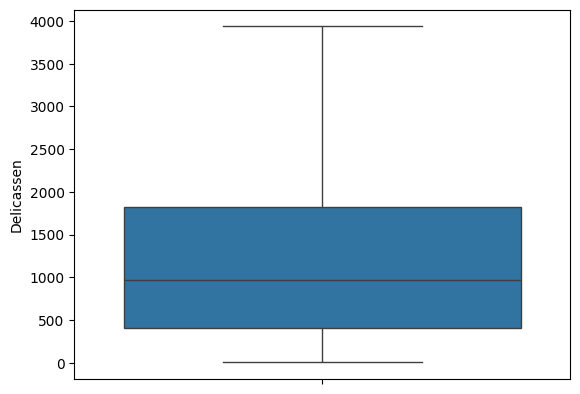

In [23]:
sns.boxplot(df['Delicassen'])

In [16]:
numerical_columns=['Fresh',	'Milk',	'Grocery','Frozen',	'Detergents_Paper',	'Delicassen']

In [17]:
for col in numerical_columns:
  Q3=df[col].quantile(0.75)
  Q1=df[col].quantile(0.25)
  IQR=Q3-Q1
  UL=Q3+1.5*IQR
  LL=Q1-1.5*IQR
  df[col]=df[col].clip(LL,UL)

In [36]:
x=df.drop(['Channel', 'Region'], axis=1)

In [35]:
from sklearn.preprocessing import StandardScaler

In [40]:
SC=StandardScaler()
x_scaled=SC.fit_transform(x)



In [41]:
from sklearn.cluster import KMeans

In [54]:
inertia=[]
for k in range(1,11):
  kmeans=KMeans(n_clusters=k,random_state=42)
  kmeans.fit(x_scaled)
  inertia.append(kmeans.inertia_)



In [55]:
inertia

[2640.0,
 1728.18863065616,
 1363.4478080374172,
 1202.4114104034982,
 1070.1467081363096,
 964.7603128985286,
 921.1434212800464,
 776.6321957417287,
 726.8755808937258,
 707.4116138312113]

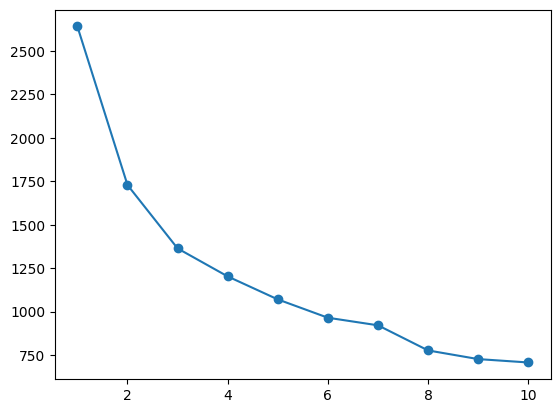

In [56]:
plt.plot(range(1,11), inertia, marker='o')

In [57]:
kmeans=KMeans(n_clusters=3,random_state=42)
kmeans.fit(x_scaled)

KMeans(n_clusters=3, random_state=42)

In [52]:
kmeans_labels=kmeans.predict(x_scaled)

In [59]:
kmeans.inertia_

1363.4478080374172

In [73]:
print(kmeans_labels)

[1 0 2 2 2 1 1 1 1 0 0 1 2 0 0 1 0 2 2 1 1 1 2 2 2 1 1 1 0 1 2 1 1 2 1 0 2
 0 0 2 2 2 0 0 0 0 0 2 0 0 1 1 2 0 1 1 0 0 1 1 1 0 1 0 1 0 1 0 2 1 2 2 1 2
 1 1 1 0 1 1 1 0 0 1 1 0 0 2 1 2 1 2 0 2 0 1 1 1 1 1 0 0 1 2 1 1 0 0 1 0 1
 0 2 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 1 2 1 1 1 1 1 1 1 1 2 1 2 2 2 1 1 0 1 1
 1 1 1 1 1 1 1 0 0 1 0 0 0 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 2 2 1 1 2 2 0 2 1
 1 1 1 0 0 1 1 1 0 1 2 2 0 1 1 0 0 2 1 1 0 1 1 1 0 1 0 1 1 0 0 0 1 0 1 1 0
 1 1 1 1 2 1 1 1 2 1 1 1 2 1 1 1 1 2 2 1 1 1 0 0 1 1 1 1 1 0 2 2 2 1 1 1 2
 2 1 1 1 1 0 2 0 2 0 1 1 1 1 2 1 1 2 1 1 1 1 1 2 2 2 1 1 2 1 1 1 1 1 0 1 1
 1 1 1 1 1 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 1 1 1 2 1 1 2 1 1 0 2
 0 2 2 1 1 1 2 0 0 1 0 1 1 0 2 1 0 1 0 1 0 2 1 1 0 2 1 1 1 1 1 1 0 1 1 1 1
 2 2 2 2 1 1 0 2 1 1 1 2 2 1 2 1 1 1 1 1 1 1 1 2 1 1 0 1 1 1 1 2 1 1 1 1 2
 0 1 2 1 2 1 2 1 1 0 1 0 1 0 1 1 1 1 2 0 2 1 1 1 2 1 1 1 2 2 0 1 1]


In [71]:
from sklearn.cluster import DBSCAN
dbscan=DBSCAN(eps=1.5,min_samples=5)

dbscan_labels=dbscan.fit_predict(x_scaled)

In [72]:
print(dbscan_labels)

[ 0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1
  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0 -1
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0 -1  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0 -1  0  0
  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0 -1  0  0  0  0  0  0  0  0  0 -1  0 -1  0  0  0 -1  0  0  0  0
  0  0  0  0  0  0  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0 -1 -1  0  0  0  0  0  0  0  0  0
  0 -1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0 -1  0  0  0  0  0  0  0  0  0 -1  0  0  0

In [76]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)
x_pca

array([[ 7.61234254e-01, -3.11172466e-01],
       [ 1.14352013e+00, -6.40064013e-02],
       [ 1.33066653e+00,  1.06306195e+00],
       [-1.19811353e+00,  1.25719766e+00],
       [ 2.97408714e-01,  2.33671510e+00],
       [ 2.48210355e-01, -3.48731010e-01],
       [-1.62672232e-01, -8.86694325e-01],
       [ 7.12260292e-01,  1.79849874e-01],
       [-3.33901655e-01, -1.08511795e+00],
       [ 3.00094073e+00, -2.19364612e-01],
       [ 1.30696627e+00,  1.03985852e-01],
       [-1.18706305e+00, -5.86356951e-01],
       [ 1.81030364e+00,  1.63345666e+00],
       [ 1.35533410e+00,  2.64460881e-01],
       [ 1.62739201e+00,  7.16069681e-01],
       [-1.10577876e+00, -1.06213610e+00],
       [ 1.47496579e+00, -1.22112148e+00],
       [ 8.63710737e-02,  6.94840924e-01],
       [ 8.19068364e-01,  1.31632870e+00],
       [-1.22080403e-01, -1.10233944e+00],
       [-1.28968516e-01,  4.12323445e-01],
       [-1.47566256e+00, -5.25037231e-01],
       [-5.41418445e-01,  3.62724571e+00],
       [ 3.

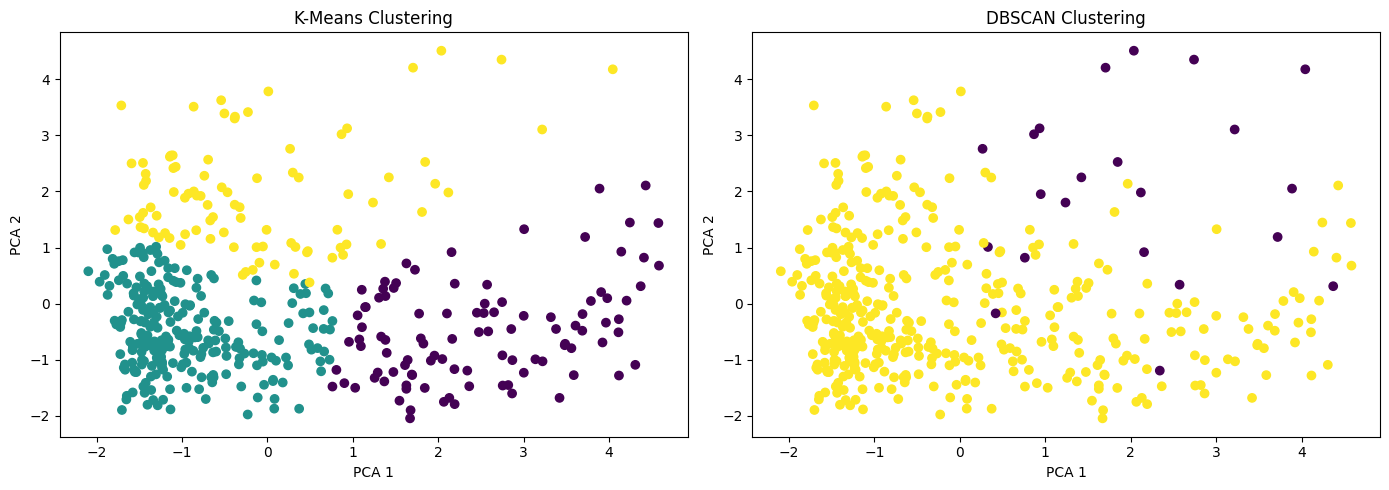

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means
axes[0].scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)

axes[0].set_title('K-Means Clustering')
axes[0].set_xlabel('PCA 1')
axes[0].set_ylabel('PCA 2')

# DBSCAN
axes[1].scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)

axes[1].set_title('DBSCAN Clustering')
axes[1].set_xlabel('PCA 1')
axes[1].set_ylabel('PCA 2')

plt.tight_layout()
plt.show()

In [78]:
import numpy as np
import pandas as pd

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN'],
    'Number of Clusters': [
        len(set(kmeans_labels)),
        len(set(dbscan_labels) - {-1})
    ],
    'Noise Points': [
        0,
        sum(dbscan_labels == -1)
    ]
})

comparison

,Algorithm,Number of Clusters,Noise Points
0,K-Means,3,0
1,DBSCAN,1,22
